# **Análisis espacial de inundaciones en Puerto Pizarro, Tumbes**

Análisis mediante imágenes satelitales Sentinel-1 SAR | 2026-II

Curso: Análisis Espacial
Docente: Fabián Drenkhan

Integrantes:

*   Sonaly Valdiviezo
*   Ana Alata
* Jimena Tamariz
* Valeria Valer

Periodo: 2026-II

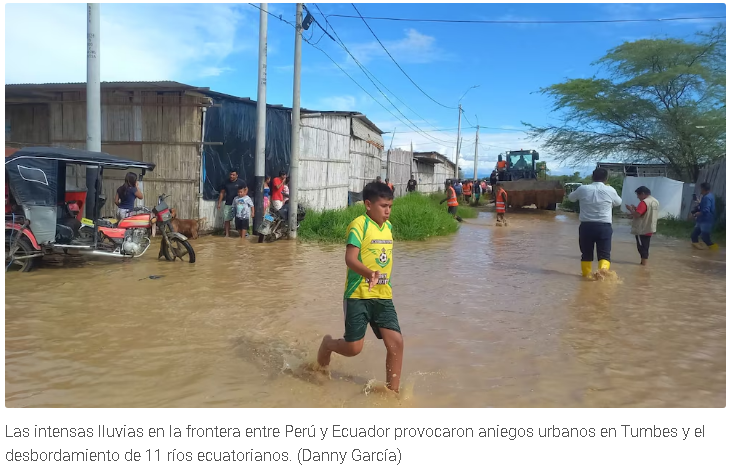

###**0. Introducción y objetivos**
*0.1 Introducción*


Explicar que el trabajo busca identificar y analizar posibles áreas inundadas en Puerto Pizarro, Tumbes, durante el año 2026, utilizando imágenes Sentinel-1 SAR.

*0.2 Objetivo general*


Identificar y delimitar las áreas potencialmente afectadas por inundaciones en Puerto Pizarro mediante el análisis comparativo de imágenes Sentinel-1 SAR correspondientes a periodos anteriores y posteriores a un evento de inundación en 2026.


*0.3 Objetivos específicos*
- Obtener y procesar imágenes Sentinel-1 SAR.
- Generar composiciones de imágenes para los periodos ex ante y ex post.
- Calcular imágenes de diferencia para identificar cambios en la retrodispersión.
- Determinar umbrales para detectar posibles superficies inundadas.
- Delimitar y visualizar las áreas afectadas mediante mapas e histogramas.

### **1. Selección y delimitación del área de interés (AOI)**

**Área seleccionada: Villa Puerto Pizarro, provincia y departamento de Tumbes, Perú.**

Se seleccionó Villa Puerto Pizarro como área de estudio debido a su exposición a eventos de inundación asociados con las precipitaciones intensas y a sus características geomorfológicas y costeras. Su ubicación en la desembocadura del río Tumbes, próxima al océano Pacífico y a los ecosistemas de manglares, configura un territorio susceptible a la acumulación de agua y a diferentes procesos de inundación.

**1.1 Importación de librerías**

Codigo para: Importar las herramientas necesarias:
- Earth Engine.
- Geemap.
- Librerías para procesamiento y visualización.

In [ ]:
# Instalar las librerías necesarias
!pip install -q earthengine-api geemap

In [ ]:
# Importar librerías esenciales: Earth Engine Python API, geemap
import ee                  # Permite acceder a Google Earth Engine
import geemap              # Permite visualizar imágenes satelitales y mapas interactivos

import numpy as np         # Permite realizar operaciones matemáticas con matrices
import pandas as pd        # Permite organizar y manipular tablas de datos

import matplotlib.pyplot as plt  # Permite elaborar gráficos e histogramas
import seaborn as sns             # Facilita la visualización de datos estadísticos

import geopandas as gpd    # Permite trabajar con información geográfica vectorial

from datetime import datetime, timedelta  # Permite manejar fechas y periodos temporales

plt.rcParams['figure.figsize'] = (10, 6)  # Define el tamaño predeterminado de los gráficos
plt.rcParams['figure.dpi'] = 100          # Establece la resolución de los gráficos
sns.set_style('whitegrid')                # Configura el estilo visual de los gráficos

print("Librerías importadas correctamente")  # Confirma la importación de las librerías

Librerías importadas correctamente


**1.2 Autenticación e inicialización de Google Earth Engine**

Codigo para: Autenticar tu cuenta e iniciar la conexión con Earth Engine.

In [ ]:
# Autenticar e iniciar sesión de GEE en Colab usando el método nativo de Google Colab
from google.colab import auth
try:
    auth.authenticate_user()  # Autenticación nativa de Colab
    print("Autenticación de usuario de Colab exitosa")
except Exception as e:
    print(f"No se pudo realizar la autenticación nativa: {e}")
    print("Intentando con ee.Authenticate()...")
    ee.Authenticate()

# Conecta con tu proyecto de Google Cloud habilitado para Earth Engine
ee.Initialize(project='ee-a20221914')

print("Conexión exitosa con Earth Engine")

Autenticación de usuario de Colab exitosa
Conexión exitosa con Earth Engine


**1.3 Visualización del área de estudio y Delimitación del área de interés**

Codigo para:
1. Crear un mapa satelital interactivo
mediante Geemap.
2. Dibujar un rectángulo o polígono que delimite Puerto Pizarro.

In [ ]:
# Definir las coordenadas centrales de Puerto Pizarro
centro_lat = -3.5034
centro_lon = -80.3899

# Crear mapa interactivo centrado en Puerto Pizarro
Map = geemap.Map(center=[centro_lat, centro_lon], zoom=13)

# Establecer el mapa base satelital
Map.add_basemap('SATELLITE')

# Mostrar el mapa
Map

Map(center=[-3.5034, -80.3899], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topr…

In [ ]:
# Crear un punto central en Puerto Pizarro
centro = ee.Geometry.Point([centro_lon, centro_lat])

# Crear un cuadrado de 5 km por lado alrededor del centro
aoi = centro.buffer(2500).bounds()

# Agregar el cuadrado al mapa con borde rojo
Map.addLayer(aoi, {'color': 'red'}, 'Área de estudio')

# Mostrar el mapa
Map

Map(center=[-3.5034, -80.3899], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topr…

In [ ]:
# Calcular la superficie del cuadrado en km²
area = aoi.area(maxError=1).divide(1000000).getInfo()
# maxError=1: establece un margen de error de 1 metro para el cálculo geométrico.
# divide(1000000): convierte metros cuadrados a kilómetros cuadrados.
# getInfo(): obtiene el resultado del cálculo.

# Mostrar la superficie
print(f"Área de estudio: {area:.2f} km²")

Área de estudio: 24.86 km²


**1.5 Identificación de límites administrativos**

Utilizar la colección FAO GAUL 2025 para identificar la provincia correspondiente.
* Nombre del departamento.
* Nombre de la provincia (GAUL2_NAME).
* Coordenadas.
* Superficie del área delimitada.

In [ ]:
#Cargar las colecciones FAO GAUL 2025
# Cargar los límites administrativos de primer nivel (departamentos)
gaul1 = ee.FeatureCollection('FAO/GAUL/2025/level1')

# Cargar los límites administrativos de segundo nivel (provincias)
gaul2 = ee.FeatureCollection('FAO/GAUL/2025/level2')

# Filtrar los límites correspondientes a Perú
gaul1 = gaul1.filter(ee.Filter.eq('GAUL0_NAME', 'Peru'))
gaul2 = gaul2.filter(ee.Filter.eq('GAUL0_NAME', 'Peru'))

In [ ]:
# Identificar departamento y provincia
# Identificar el departamento que intersecta el área de estudio
departamento = gaul1.filterBounds(aoi)

# Identificar la provincia que intersecta el área de estudio
provincia = gaul2.filterBounds(aoi)

# Extraer el nombre del departamento
nombre_departamento = departamento.aggregate_array('GAUL1_NAME').distinct().getInfo()

# Extraer el nombre de la provincia
nombre_provincia = provincia.aggregate_array('GAUL2_NAME').distinct().getInfo()

# Mostrar los resultados
print('Departamento:', nombre_departamento)
print('Provincia:', nombre_provincia)

Departamento: ['Tumbes']
Provincia: ['Tumbes', 'Zarumilla']


In [ ]:
# Extraer coordenadas y superficie
# Obtener las coordenadas centrales del área de estudio
coordenadas = aoi.centroid(maxError=1).coordinates().getInfo()

# Calcular la superficie del área delimitada en km²
superficie = aoi.area(maxError=1).divide(1000000).getInfo()

# Mostrar la información geográfica
print('Coordenadas centrales (longitud, latitud):', coordenadas)
print(f'Superficie del área de estudio: {superficie:.2f} km²')

Coordenadas centrales (longitud, latitud): [-80.38986457828541, -3.503395763819643]
Superficie del área de estudio: 24.86 km²


In [ ]:
#Visualizar los límites administrativos
# Agregar los límites departamentales al mapa
Map.addLayer(departamento, {'color': 'yellow'}, 'Departamento')

# Agregar los límites provinciales al mapa
Map.addLayer(provincia, {'color': 'cyan'}, 'Provincia')

# Agregar el área de estudio en color rojo
Map.addLayer(aoi, {'color': 'red'}, 'AOI Puerto Pizarro')

# Mostrar el mapa
Map

Map(bottom=534869.0, center=[-3.5274707159569605, -80.40944169438772], controls=(WidgetControl(options=['posit…

### **2. Selección y adquisición de imágenes Sentinel-1 SAR**

Obtener las imágenes satelitales que permitirán comparar las condiciones del territorio antes y después de una inundación.

**2.1 Características de Sentinel-1 SAR**

Criterios de selección:
- Modo IW: adecuado para el análisis de superficies terrestres y zonas costeras, por su amplia cobertura y resolución espacial.
- Polarización VV y VH: se utiliza polarización dual. VV permite identificar superficies de agua por su baja retrodispersión, mientras que VH aporta información complementaria sobre vegetación y dispersión volumétrica.
- Resolución espacial: 10 metros.
- Producto: Sentinel-1 GRD.


In [ ]:
# Definir las características y los periodos
# Definir el modo de adquisición del sensor
modo = 'IW'  # Interferometric Wide Swath

# Definir las polarizaciones
polarizacion = ['VV', 'VH']  # Polarización dual

# Definir la resolución espacial
resolucion = 10  # Resolución en metros

# Definir el periodo ex ante
fecha_pre_inicio = '2026-10-25'
fecha_pre_fin = '2026-11-01'  # Fecha final excluida

# Definir el periodo ex post
fecha_post_inicio = '2026-11-06'
fecha_post_fin = '2026-11-13'  # Fecha final excluida

# Mostrar los parámetros seleccionados
print('Modo del instrumento:', modo)
print('Polarizaciones:', polarizacion)
print('Resolución espacial:', resolucion, 'm')
print('Periodo ex ante:', fecha_pre_inicio, 'a', fecha_pre_fin)
print('Periodo ex post:', fecha_post_inicio, 'a', fecha_post_fin)

Modo del instrumento: IW
Polarizaciones: ['VV', 'VH']
Resolución espacial: 10 m
Periodo ex ante: 2026-10-25 a 2026-11-01
Periodo ex post: 2026-11-06 a 2026-11-13


**2.2 Definir los periodos y seleccionar datos Sentinel-1 GRD**

Cargar y filtrar la colección Sentinel-1

In [ ]:
# Cargar la colección Sentinel-1 GRD
sentinel1 = ee.ImageCollection('COPERNICUS/S1_GRD')

# Filtrar imágenes según el área de estudio y las características seleccionadas
sentinel1 = (sentinel1
    .filterBounds(aoi)  # Limitar al área de estudio
    .filter(ee.Filter.eq('instrumentMode', modo))  # Seleccionar modo IW
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))  # Incluir VV
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))  # Incluir VH
    .filter(ee.Filter.eq('resolution_meters', resolucion))  # Seleccionar resolución de 10 m
)

# Separar las imágenes del periodo ex ante
s1_pre = sentinel1.filterDate(fecha_pre_inicio, fecha_pre_fin)

# Separar las imágenes del periodo ex post
s1_post = sentinel1.filterDate(fecha_post_inicio, fecha_post_fin)

**2.3 Verificación de disponibilidad de imágenes**

Contabilizar las imágenes disponibles

In [ ]:
# Calcular el número total de imágenes disponibles en ambos periodos
total_imagenes = s1_pre.size().add(s1_post.size()).getInfo()

# Calcular el número de imágenes del periodo ex ante
total_pre = s1_pre.size().getInfo()

# Calcular el número de imágenes del periodo ex post
total_post = s1_post.size().getInfo()

# Mostrar los resultados
print('Número total de imágenes:', total_imagenes)
print('Número de imágenes ex ante:', total_pre)
print('Número de imágenes ex post:', total_post)

Número total de imágenes: 4
Número de imágenes ex ante: 1
Número de imágenes ex post: 3


Identificar las fechas de adquisición

In [ ]:
# Obtener las fechas de las imágenes ex ante
fechas_pre = s1_pre.aggregate_array('system:time_start').getInfo()

# Obtener las fechas de las imágenes ex post
fechas_post = s1_post.aggregate_array('system:time_start').getInfo()

# Convertir y mostrar las fechas ex ante
print('Fechas de adquisición ex ante:')
for fecha in fechas_pre:
    print(ee.Date(fecha).format('YYYY-MM-dd').getInfo())

# Convertir y mostrar las fechas ex post
print('\nFechas de adquisición ex post:')
for fecha in fechas_post:
    print(ee.Date(fecha).format('YYYY-MM-dd').getInfo())

Fechas de adquisición ex ante:
2026-10-30

Fechas de adquisición ex post:
2026-11-11
2026-11-08
2026-11-08


Visualizar las imágenes disponibles

In [ ]:
# Mostrar la primera imagen ex ante si existe
if total_pre > 0:
    imagen_pre = ee.Image(s1_pre.first())
    Map.addLayer(imagen_pre.select('VV'),
                 {'min': -25, 'max': 0},
                 'Sentinel-1 VV ex ante')

# Mostrar la primera imagen ex post si existe
if total_post > 0:
    imagen_post = ee.Image(s1_post.first())
    Map.addLayer(imagen_post.select('VV'),
                 {'min': -25, 'max': 0},
                 'Sentinel-1 VV ex post')

# Mostrar el mapa
Map

Map(bottom=1069231.0, center=[-3.492003458564937, -80.37691340472573], controls=(WidgetControl(options=['posit…

### **3. Composiciones de bandas, diferencia de bandas y visualizaciones**

Generar composiciones representativas de las condiciones de la superficie antes y después del evento de inundación.

**3.1. Generación de composiciones de imágenes Sentinel-1 SAR**
Se generarán composiciones de imágenes Sentinel-1 SAR para los periodos ex ante y ex post del evento de inundación en Puerto Pizarro. Para ello, se utilizará el valor de la mediana de las imágenes disponibles en cada periodo, con la finalidad de obtener una representación estadística de la respuesta de retrodispersión de la superficie.

Código:
- Crear composición mediana ex ante.
- Crear composición mediana ex post.
- Recortar ambas composiciones al área de interés (clip).

In [ ]:
# Crear composiciones de imágenes Sentinel-1 SAR para los periodos ex ante y ex post

# Seleccionar la banda VV para el análisis de inundaciones
banda = 'VV'

# Crear la composición mediana del periodo ex ante
composicion_pre = s1_pre.select(banda).median().clip(aoi)

# Crear la composición mediana del periodo ex post
composicion_post = s1_post.select(banda).median().clip(aoi)

# Confirmar la creación de las composiciones
print('Composición mediana ex ante creada correctamente')
print('Composición mediana ex post creada correctamente')

Composición mediana ex ante creada correctamente
Composición mediana ex post creada correctamente


**3.2. Reducción del ruido de moteado (Speckle Noise)**

Las imágenes SAR presentan un ruido característico denominado speckle noise, que puede dificultar la identificación de cambios en la superficie. Para reducir este efecto, se aplicará un filtro de mediana focal (focal_median) sobre las composiciones ex ante y ex post, utilizando un radio espacial definido en metros.

Código:
- Definir el radio del filtro (20–50 m).
- Aplicar focal_median a la composición ex ante.
- Aplicar focal_median a la composición ex post.


In [ ]:
# Reducir el ruido de moteado (speckle noise) de las imágenes Sentinel-1 SAR

# Definir el radio del filtro de mediana espacial
radio_filtro = 30  # Radio de 30 metros

# Aplicar el filtro de mediana focal a la composición ex ante
composicion_pre_filtrada = composicion_pre.focal_median(
    radius=radio_filtro,
    units='meters'
)

# Aplicar el filtro de mediana focal a la composición ex post
composicion_post_filtrada = composicion_post.focal_median(
    radius=radio_filtro,
    units='meters'
)

# Mostrar el parámetro utilizado
print('Filtro de mediana aplicado correctamente')
print('Radio del filtro:', radio_filtro, 'metros')

Filtro de mediana aplicado correctamente
Radio del filtro: 30 metros


**3.3. Visualización de composiciones ex ante y ex post**

Se visualizarán las composiciones generadas mediante una escala de colores que permita interpretar los valores de retrodispersión de las imágenes Sentinel-1. Se utilizarán los mismos parámetros de visualización para facilitar la comparación entre ambos periodos.

Código:
- Definir valores mínimos y máximos.
- Establecer una paleta de colores.
- Visualizar la composición ex ante.
- Visualizar la composición ex post.


In [ ]:
# Visualizar las composiciones Sentinel-1 SAR ex ante y ex post

# Definir los parámetros de visualización de la banda VV
visualizacion_sar = {
    'min': -25,
    'max': 0,
    'palette': [
        '#000000',  # Negro
        '#333333',  # Gris muy oscuro
        '#666666',  # Gris oscuro
        '#999999',  # Gris intermedio
        '#CCCCCC',  # Gris claro
        '#FFFFFF'   # Blanco
    ]
}

# Visualizar la composición filtrada ex ante
Map.addLayer(
    composicion_pre_filtrada,
    visualizacion_sar,
    'Composición ex ante VV'
)

# Visualizar la composición filtrada ex post
Map.addLayer(
    composicion_post_filtrada,
    visualizacion_sar,
    'Composición ex post VV'
)

# Centrar el mapa en el área de estudio de Puerto Pizarro
Map.centerObject(aoi, 13)

# Mostrar el mapa
Map


Map(bottom=1069297.0, center=[-3.503395588693487, -80.38986457828541], controls=(WidgetControl(options=['posit…

**3.4. Cálculo de la imagen de diferencia**

Se calculará la diferencia entre las composiciones ex ante y ex post mediante la resta de sus valores de retrodispersión. Este procedimiento permitirá identificar cambios en la respuesta de la superficie terrestre entre ambos periodos, los cuales podrían estar relacionados con la presencia de agua.

Código:
- Restar la composición ex post a la composición ex ante.
- Recortar el resultado al área de interés.
- Almacenar la imagen de diferencia en una nueva variable.


In [ ]:
# Calcular la imagen de diferencia entre las composiciones ex ante y ex post

# Restar la composición ex post a la composición ex ante
imagen_diferencia = composicion_pre_filtrada.subtract(composicion_post_filtrada)

# Recortar la imagen de diferencia al área de estudio de Puerto Pizarro
imagen_diferencia = imagen_diferencia.clip(aoi)

# Confirmar la creación de la imagen de diferencia
print('Imagen de diferencia creada correctamente')


Imagen de diferencia creada correctamente


**3.5. Visualización de la imagen de diferencia**

La imagen de diferencia se representará mediante una escala divergente de seis colores, desde tonos azules hasta rojos, para distinguir los diferentes valores de cambio en la retrodispersión. Los valores mínimos y máximos de visualización se ajustarán para mejorar la interpretación espacial de los resultados.

Código:
- Definir valores mínimos y máximos (por ejemplo, -10 a +10).
- Crear paleta divergente de seis colores.
- Agregar la imagen de diferencia al mapa.
- Centrar el mapa en el área de estudio.

In [ ]:
# Visualizar la imagen de diferencia de retrodispersión de Sentinel-1 SAR

# Definir los parámetros de visualización de la imagen de diferencia
visualizacion_diferencia = {
    'min': -10,
    'max': 10,
    'palette': [
        '#2166AC',  # Azul oscuro
        '#67A9CF',  # Azul claro
        '#D1E5F0',  # Celeste
        '#FDDBC7',  # Naranja claro
        '#EF8A62',  # Naranja
        '#B2182B'   # Rojo oscuro
    ]
}

# Agregar la imagen de diferencia al mapa
Map.addLayer(
    imagen_diferencia,
    visualizacion_diferencia,
    'Diferencia ex ante - ex post'
)

# Centrar el mapa en el área de estudio de Puerto Pizarro
Map.centerObject(aoi, 13)

# Mostrar el mapa
Map


Map(bottom=134012.0, center=[-3.5033955886934876, -80.38986457828541], controls=(WidgetControl(options=['posit…

### **4. Determinación iterativa de parámetros y umbrales**

Establecer los parámetros y umbrales que permitan identificar cambios asociados a posibles superficies inundadas.

**4.1. Definición de umbrales de retrodispersión de las imágenes originales**

Se establecerán umbrales iniciales sobre los valores de retrodispersión de las composiciones Sentinel-1 SAR. Las superficies de agua libre suelen presentar valores bajos de retrodispersión debido a la reflexión especular de la señal del radar. Se evaluarán estos valores en las composiciones ex ante y ex post para reconocer posibles superficies de agua.
Código:
- Definir un umbral inicial de retrodispersión.
- Identificar los píxeles que cumplen dicha condición.
- Visualizar los resultados sobre las composiciones originales.
- Comparar el comportamiento de los valores antes y después del evento.

In [ ]:
# Identificar posibles superficies de agua mediante un umbral de retrodispersión

# Definir el umbral inicial de retrodispersión para la banda VV
umbral_agua = -17  # Valor inicial en decibelios (dB)

# Identificar los píxeles con retrodispersión menor al umbral ex ante
agua_pre = composicion_pre.lt(umbral_agua).selfMask()

# Identificar los píxeles con retrodispersión menor al umbral ex post
agua_post = composicion_post.lt(umbral_agua).selfMask()

# Definir los parámetros de visualización de las posibles superficies de agua
visualizacion_agua = {
    'min': 0,
    'max': 1,
    'palette': ['#00BFFF']
}

# Agregar las posibles superficies de agua ex ante al mapa
Map.addLayer(
    agua_pre,
    visualizacion_agua,
    'Posible agua ex ante',
    False
)

# Agregar las posibles superficies de agua ex post al mapa
Map.addLayer(
    agua_post,
    visualizacion_agua,
    'Posible agua ex post',
    True
)

# Centrar el mapa en el área de estudio de Puerto Pizarro
Map.centerObject(aoi, 13)

# Mostrar el umbral utilizado
print('Umbral inicial de retrodispersión:', umbral_agua, 'dB')

# Mostrar el mapa
Map

Umbral inicial de retrodispersión: -17 dB


Map(bottom=1069408.0, center=[-3.5033955886934876, -80.38986457828541], controls=(WidgetControl(options=['posi…

Comparación visual de los umbrales de diferencia (1, 2 y 3 dB)

In [ ]:

# Crear un mapa independiente para comparar los umbrales de diferencia

# Crear un nuevo mapa centrado en Puerto Pizarro
Mapa_umbrales = geemap.Map(center=[centro_lat, centro_lon], zoom=13)

# Agregar imágenes satelitales de Esri como mapa base
Mapa_umbrales.add_basemap('Esri.WorldImagery')

# Desactivar el mapa base de OpenStreetMap
Mapa_umbrales.layers[0].visible = False

# Definir los umbrales de diferencia que se evaluarán
umbrales_diferencia = [1, 2, 3]

# Definir los parámetros de visualización de los cambios
visualizacion_cambio = {
    'min': 0,
    'max': 1,
    'palette': ['#FF0000']
}

# Aplicar los umbrales a la imagen de diferencia
for umbral in umbrales_diferencia:

    # Identificar los píxeles que superan cada umbral
    cambio = imagen_diferencia.gt(umbral).selfMask()

    # Agregar los resultados al mapa
    Mapa_umbrales.addLayer(
        cambio,
        visualizacion_cambio,
        'Cambio mayor a ' + str(umbral) + ' dB',
        umbral == 1
    )

# Centrar el mapa en el área de estudio de Puerto Pizarro
Mapa_umbrales.centerObject(aoi, 13)

# Mostrar los umbrales evaluados
print('Umbrales de diferencia evaluados:', umbrales_diferencia)

# Mostrar el mapa
Mapa_umbrales


Umbrales de diferencia evaluados: [1, 2, 3]


Map(center=[-3.5033955886934876, -80.38986457828541], controls=(WidgetControl(options=['position', 'transparen…

**4.2. Determinación del umbral de la imagen de diferencia**

Se evaluarán diferentes umbrales sobre la imagen de diferencia para identificar cambios en la retrodispersión potencialmente asociados a inundaciones. La selección del umbral se realizará de manera iterativa, considerando el sentido de la resta entre las imágenes ex ante y ex post, así como la distribución espacial de los cambios detectados.
Código:
- Definir un umbral inicial de diferencia.
- Aplicar el umbral a la imagen de diferencia.
- Identificar los píxeles que cumplen la condición.
- Probar diferentes valores de umbral.
- Comparar los resultados mediante visualizaciones.

In [ ]:
# Definir un umbral inicial de diferencia
umbral_inicial = 1

# Definir los diferentes umbrales que se evaluarán
umbrales_diferencia = [1, 2, 3]

# Aplicar el umbral inicial a la imagen de diferencia
cambio_inicial = imagen_diferencia.gt(umbral_inicial).selfMask()

# Identificar los píxeles que cumplen la condición
# Los valores positivos indican una disminución de retrodispersión
print('Umbral inicial:', umbral_inicial, 'dB')

# Crear un mapa para comparar los resultados
Mapa_umbrales = geemap.Map(center=[centro_lat, centro_lon], zoom=13)

# Agregar imágenes satelitales de Esri como mapa base
Mapa_umbrales.add_basemap('Esri.WorldImagery')

# Desactivar el mapa base de OpenStreetMap
Mapa_umbrales.layers[0].visible = False

# Definir los parámetros de visualización
visualizacion_cambio = {
    'min': 0,
    'max': 1,
    'palette': ['#FF0000']
}

# Probar diferentes valores de umbral
for umbral in umbrales_diferencia:

    # Aplicar cada umbral a la imagen de diferencia
    cambio = imagen_diferencia.gt(umbral).selfMask()

    # Agregar los píxeles identificados al mapa
    Mapa_umbrales.addLayer(
        cambio,
        visualizacion_cambio,
        'Cambio mayor a ' + str(umbral) + ' dB',
        umbral == 1
    )

# Seleccionar provisionalmente el umbral de 2 dB
umbral_seleccionado = 2

# Generar la imagen de cambios con el umbral seleccionado
cambio_seleccionado = imagen_diferencia.gt(umbral_seleccionado).selfMask()

# Mostrar los umbrales evaluados
print('Umbrales evaluados:', umbrales_diferencia)
print('Umbral seleccionado:', umbral_seleccionado, 'dB')

# Centrar el mapa en Puerto Pizarro
Mapa_umbrales.centerObject(aoi, 13)

# Mostrar el mapa para comparar los resultados
Mapa_umbrales


Umbral inicial: 1 dB
Umbrales evaluados: [1, 2, 3]
Umbral seleccionado: 2 dB


Map(center=[-3.5033955886934876, -80.38986457828541], controls=(WidgetControl(options=['position', 'transparen…

Nota: A partir de este apartado, se utiliza Esri.WorldImagery como mapa base, ya que permite distinguir visualmente los manglares, canales de agua, zonas costeras y otras características del área de estudio de Puerto Pizarro, facilitando la identificación y comparación espacial de los cambios de retrodispersión.

**4.3. Evaluación y selección de parámetros finales**

Se compararán los resultados obtenidos con diferentes configuraciones de umbrales y parámetros de procesamiento. Se seleccionarán los valores que permitan representar de manera más consistente los cambios asociados a posibles inundaciones en Puerto Pizarro.
Código:
- Comparar diferentes umbrales.
- Evaluar los cambios identificados.
- Seleccionar los parámetros finales.
- Registrar los valores utilizados en el análisis

In [ ]:
# Definir los umbrales evaluados anteriormente
umbrales_evaluados = [1, 2, 3]

# Definir la resolución espacial de análisis
resolucion = 10

# Comparar los cambios identificados con cada umbral
print('COMPARACIÓN DE UMBRALES DE DIFERENCIA')

for umbral in umbrales_evaluados:

    # Identificar los píxeles que superan cada umbral
    cambio = imagen_diferencia.gt(umbral)

    # Calcular el área de los cambios detectados en metros cuadrados
    area_cambio = ee.Image.pixelArea().updateMask(cambio).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=aoi,
        scale=resolucion,
        maxPixels=1e9
    ).get('area')

    # Convertir el área de metros cuadrados a hectáreas
    area_ha = ee.Number(area_cambio).divide(10000)

    # Mostrar el área identificada para cada umbral
    print('Umbral:', umbral, 'dB - Área de cambio:',
          round(area_ha.getInfo(), 2), 'ha')

# Seleccionar los parámetros finales del análisis
umbral_final = 2
radio_filtro_final = 30
banda_final = 'VV'

# Aplicar el umbral seleccionado a la imagen de diferencia
cambio_final = imagen_diferencia.gt(umbral_final).selfMask()

# Registrar los parámetros utilizados
print('\nPARÁMETROS FINALES DEL ANÁLISIS')
print('Área de estudio: Puerto Pizarro, Tumbes')
print('Satélite: Sentinel-1 SAR')
print('Banda utilizada:', banda_final)
print('Resolución espacial:', resolucion, 'metros')
print('Filtro de mediana:', radio_filtro_final, 'metros')
print('Umbrales evaluados:', umbrales_evaluados, 'dB')
print('Umbral seleccionado:', umbral_final, 'dB')
print('Operación: Imagen ex ante - Imagen ex post')
print('Condición: Disminución de retrodispersión mayor a 2 dB')

# Crear un mapa con el resultado final
Mapa_final = geemap.Map(center=[centro_lat, centro_lon], zoom=13)

# Agregar imágenes satelitales de Esri como mapa base
Mapa_final.add_basemap('Esri.WorldImagery')

# Desactivar OpenStreetMap
Mapa_final.layers[0].visible = False

# Visualizar los cambios con el umbral seleccionado
Mapa_final.addLayer(
    cambio_final,
    {'min': 0, 'max': 1, 'palette': ['#FF0000']},
    'Cambios detectados - Umbral 2 dB'
)

# Centrar y mostrar el mapa
Mapa_final.centerObject(aoi, 13)
Mapa_final


COMPARACIÓN DE UMBRALES DE DIFERENCIA
Umbral: 1 dB - Área de cambio: 541.49 ha
Umbral: 2 dB - Área de cambio: 231.84 ha
Umbral: 3 dB - Área de cambio: 106.53 ha

PARÁMETROS FINALES DEL ANÁLISIS
Área de estudio: Puerto Pizarro, Tumbes
Satélite: Sentinel-1 SAR
Banda utilizada: VV
Resolución espacial: 10 metros
Filtro de mediana: 30 metros
Umbrales evaluados: [1, 2, 3] dB
Umbral seleccionado: 2 dB
Operación: Imagen ex ante - Imagen ex post
Condición: Disminución de retrodispersión mayor a 2 dB


Map(center=[-3.5033955886934876, -80.38986457828541], controls=(WidgetControl(options=['position', 'transparen…

### **5. Generación y exportación de resultados**

Generar y guardar los productos principales del análisis de cambios mediante imágenes Sentinel-1 SAR.

**5.1. Generación de imagen de diferencia final**

Se utilizarán las composiciones ex ante y ex post, junto con los parámetros seleccionados, para obtener la imagen de diferencia definitiva. Esta imagen permitirá representar los cambios en los valores de retrodispersión dentro del área de estudio.

Código:
- Aplicar los parámetros finales.
- Generar la imagen de diferencia.
- Recortar al área de interés.
- Preparar la imagen para su exportación.

In [ ]:
# Definir los parámetros finales seleccionados
banda_final = 'VV'
umbral_final = 2
resolucion = 10
radio_filtro_final = 30

# Seleccionar la banda VV de las composiciones filtradas
composicion_ex_ante_final = composicion_pre_filtrada.select(banda_final)
composicion_ex_post_final = composicion_post_filtrada.select(banda_final)

# Calcular la diferencia entre ambos periodos
# Ex ante - Ex post
imagen_diferencia_final = (
    composicion_ex_ante_final
    .subtract(composicion_ex_post_final)
    .clip(aoi)
)

# Generar la imagen de cambios aplicando el umbral seleccionado
cambio_final = imagen_diferencia_final.gt(umbral_final).selfMask()

# Confirmar la generación de los resultados
print('Imagen de diferencia final generada correctamente')
print('Banda utilizada:', banda_final)
print('Umbral seleccionado:', umbral_final, 'dB')
print('Resolución espacial:', resolucion, 'metros')
print('Filtro de mediana:', radio_filtro_final, 'metros')

Imagen de diferencia final generada correctamente
Banda utilizada: VV
Umbral seleccionado: 2 dB
Resolución espacial: 10 metros
Filtro de mediana: 30 metros


**5.2. Exportación de imagen de diferencia**
La imagen de diferencia final será exportada desde Google Earth Engine en formato ráster GeoTIFF, conservando la información espacial y los valores digitales necesarios para su posterior consulta y visualización.

Código:
- Definir región de exportación.
- Establecer resolución espacial.
- Configurar sistema de referencia.
- Exportar imagen a Google Drive.

Producto 1: Imagen de diferencia exportada.


In [ ]:
# Definir el sistema de referencia espacial de la imagen
sistema_referencia = imagen_diferencia_final.projection().crs().getInfo()

# Configurar la exportación a Google Drive
tarea_exportacion = ee.batch.Export.image.toDrive(
    image=imagen_diferencia_final,
    description='Diferencia_Sentinel1_Puerto_Pizarro',
    folder='Resultados_Sentinel1',
    fileNamePrefix='Diferencia_Sentinel1_Puerto_Pizarro',
    region=aoi,
    scale=resolucion,
    crs=sistema_referencia,
    fileFormat='GeoTIFF',
    maxPixels=1e13
)

# Iniciar la exportación
tarea_exportacion.start()

print('Exportación iniciada correctamente')
print('Formato: GeoTIFF')
print('Resolución espacial:', resolucion, 'metros')
print('Sistema de referencia:', sistema_referencia)
print('Destino: Google Drive / Resultados_Sentinel1')

Exportación iniciada correctamente
Formato: GeoTIFF
Resolución espacial: 10 metros
Sistema de referencia: EPSG:4326
Destino: Google Drive / Resultados_Sentinel1


### **6. Análisis estadístico de resultados**

Representar e interpretar los resultados obtenidos mediante gráficos y visualizaciones espaciales.

**6.1 Histograma de distribución de valores de la imagen de diferencia**

Se elaborará un histograma para representar la distribución de los valores digitales de la imagen de diferencia. Esta visualización permitirá identificar la concentración de píxeles, la dispersión de los valores y los rangos asociados a los cambios de retrodispersión. Asimismo, se señalará el umbral seleccionado para facilitar su interpretación.

Código:
- Extraer los valores de la imagen de diferencia.
- Calcular su distribución de frecuencias.
- Generar el histograma.
- Incorporar título, etiquetas y umbral seleccionado.
Producto 2
 Histograma de distribución de valores.

ANÁLISIS ESTADÍSTICO DE LA IMAGEN DE DIFERENCIA
Número de píxeles: 251000
Valor mínimo: -15.07 dB
Valor máximo: 16.39 dB
Media: -0.26 dB
Mediana: -0.26 dB
Desviación estándar: 2.25 dB


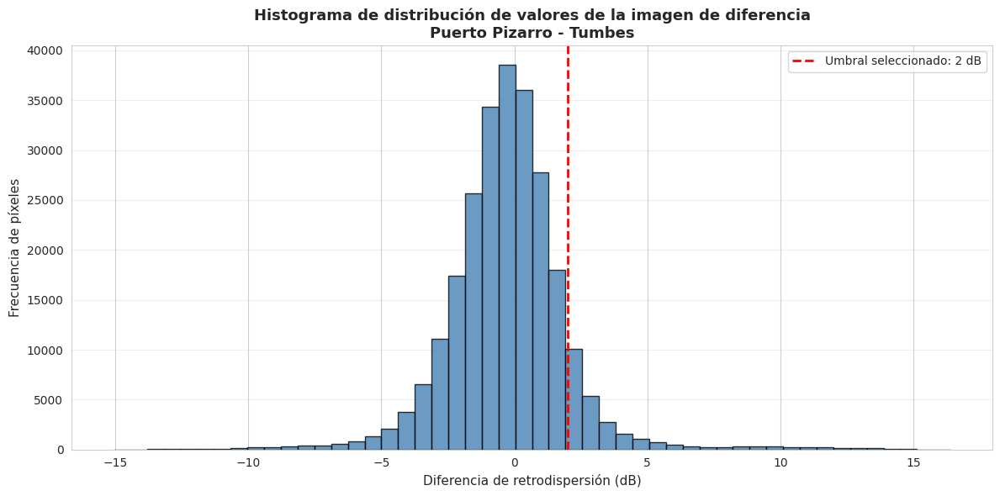

In [ ]:
# Extraer los valores de la imagen de diferencia final
# Se utiliza la banda VV y una resolución de 10 metros

datos_diferencia = geemap.ee_to_numpy(
    imagen_diferencia_final,
    bands=['VV'],
    region=aoi,
    scale=10
)

# Convertir los datos extraídos en un arreglo unidimensional
valores = np.asarray(datos_diferencia).squeeze().flatten()

# Eliminar valores vacíos o no válidos
valores = valores[np.isfinite(valores)]

# Calcular estadísticas descriptivas
print('ANÁLISIS ESTADÍSTICO DE LA IMAGEN DE DIFERENCIA')
print('Número de píxeles:', len(valores))
print('Valor mínimo:', round(np.min(valores), 2), 'dB')
print('Valor máximo:', round(np.max(valores), 2), 'dB')
print('Media:', round(np.mean(valores), 2), 'dB')
print('Mediana:', round(np.median(valores), 2), 'dB')
print('Desviación estándar:', round(np.std(valores), 2), 'dB')

# Definir el umbral seleccionado
umbral_final = 2

# Crear el histograma
plt.figure(figsize=(12, 6))

plt.hist(
    valores,
    bins=50,
    color='steelblue',
    edgecolor='black',
    alpha=0.8
)

# Incorporar una línea vertical para señalar el umbral
plt.axvline(
    x=umbral_final,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Umbral seleccionado: 2 dB'
)

# Configurar títulos y etiquetas
plt.title(
    'Histograma de distribución de valores de la imagen de diferencia\n'
    'Puerto Pizarro - Tumbes',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('Diferencia de retrodispersión (dB)', fontsize=11)
plt.ylabel('Frecuencia de píxeles', fontsize=11)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Mostrar el histograma
plt.show()

:**6.2 Visualización complementaria de libre elección**

Se desarrollará una visualización complementaria que permita profundizar en la interpretación de los cambios detectados en Puerto Pizarro, para comparar las condiciones de la superficie antes y después del evento de inundación.

Código:
- Seleccionar las composiciones ex ante y ex post.
- Configurar una misma escala de visualización.
- Presentar ambas imágenes en un mapa comparativo.
- Incorporar títulos y leyendas.

Producto 3: Visualización complementaria.

In [ ]:
import geemap
import ee
import ipywidgets as widgets
from ipyleaflet import SplitMapControl
from IPython.display import display

# 1. Configurar la visualización de Sentinel-1

visualizacion_sar = {
    'min': -25,
    'max': 0,
    'palette': [
        '#000000',
        '#333333',
        '#666666',
        '#999999',
        '#CCCCCC',
        '#FFFFFF'
    ]
}

# 2. Crear el contorno del área de estudio

aoi_contorno = ee.FeatureCollection([
    ee.Feature(aoi)
]).style(
    color='FF0000',
    fillColor='00000000',
    width=3
)

# 3. Crear las capas de Ex Ante y Ex Post

capa_pre = geemap.ee_tile_layer(
    composicion_pre_filtrada,
    vis_params=visualizacion_sar,
    name='EX ANTE'
)

capa_post = geemap.ee_tile_layer(
    composicion_post_filtrada,
    vis_params=visualizacion_sar,
    name='EX POST'
)

# 4. Crear mapa comparativo
Mapa_cortina = geemap.Map(
    center=[centro_lat, centro_lon],
    zoom=13
)

# Agregar mapa base satelital
Mapa_cortina.add_basemap('Esri.WorldImagery')

# Ocultar OpenStreetMap
Mapa_cortina.layers[0].visible = False

# Incorporar la cortina deslizante
cortina = SplitMapControl(
    left_layer=capa_pre,
    right_layer=capa_post
)

Mapa_cortina.add_control(cortina)

# Agregar el límite del área de estudio
Mapa_cortina.addLayer(
    aoi_contorno,
    {},
    'Área de estudio - Puerto Pizarro'
)

# Configurar tamaño del mapa
Mapa_cortina.layout.width = '100%'
Mapa_cortina.layout.height = '600px'

# 5. Crear titulo principal

titulo = widgets.HTML(
    value="""
    <div style="text-align:center; padding:10px;">
        <h2 style="color:#1F4E79; margin-bottom:5px;">
            ANÁLISIS COMPARATIVO DE INUNDACIONES
        </h2>
        <h3 style="color:#444; margin-top:5px;">
            Puerto Pizarro - Tumbes
        </h3>
        <p style="font-size:13px; color:#555;">
            Comparación temporal de imágenes Sentinel-1 SAR
            mediante cortina deslizante
        </p>
    </div>
    """
)

# 6. Crear los rótulos de los periodos

rotulos = widgets.HBox(
    [
        widgets.HTML(
            value="""
            <div style="text-align:center; color:#1F4E79;">
                <b>EX ANTE</b><br>
                <span style="font-size:12px;">
                25 octubre - 01 noviembre 2026
                </span>
            </div>
            """
        ),
        widgets.HTML(
            value="""
            <div style="text-align:center; color:#1F4E79;">
                <b>EX POST</b><br>
                <span style="font-size:12px;">
                06 - 13 noviembre 2026
                </span>
            </div>
            """
        )
    ],
    layout=widgets.Layout(
        width='100%',
        justify_content='space-around',
        padding='8px'
    )
)

# 7. Crear la leyenda de retrodispersión

leyenda = widgets.HTML(
    value="""
    <div style="
        width:90%;
        margin:auto;
        padding:12px;
        text-align:center;
        border:1px solid #cccccc;
        border-radius:8px;
        background-color:#ffffff;
        color:#222222;
    ">
        <b>LEYENDA: RETRODISPERSIÓN VV (dB)</b>

        <div style="
            height:18px;
            margin:10px auto 5px auto;
            width:85%;
            background:linear-gradient(
                to right,
                #000000,
                #333333,
                #666666,
                #999999,
                #CCCCCC,
                #FFFFFF
            );
            border:1px solid #777;
        "></div>

        <div style="
            display:flex;
            justify-content:space-between;
            width:85%;
            margin:auto;
            font-size:12px;
        ">
            <span>-25 dB</span>
            <span>-20 dB</span>
            <span>-15 dB</span>
            <span>-10 dB</span>
            <span>-5 dB</span>
            <span>0 dB</span>
        </div>

        <p style="font-size:11px; color:#555;">
            Negro: menor retrodispersión |
            Blanco: mayor retrodispersión
        </p>
    </div>
    """
)

# 8. Mostrar el mapa con título y leyenda

display(
    widgets.VBox(
        [
            titulo,
            rotulos,
            Mapa_cortina,
            leyenda
        ],
        layout=widgets.Layout(width='100%')
    )
)

# 9. Mostrar los parámetros del análisis

print('ANÁLISIS COMPARATIVO SENTINEL-1 SAR')
print('Área: Puerto Pizarro - Tumbes')
print('Sensor: Sentinel-1 SAR')
print('Banda: VV')
print('Resolución espacial:', resolucion, 'metros')
print('Escala de visualización: -25 a 0 dB')
print('Umbral de detección:', umbral_final, 'dB')
print('Periodo ex ante:', fecha_pre_inicio, 'a', fecha_pre_fin)
print('Periodo ex post:', fecha_post_inicio, 'a', fecha_post_fin)

ANÁLISIS COMPARATIVO SENTINEL-1 SAR
Área: Puerto Pizarro - Tumbes
Sensor: Sentinel-1 SAR
Banda: VV
Resolución espacial: 10 metros
Escala de visualización: -25 a 0 dB
Umbral de detección: 2 dB
Periodo ex ante: 2026-10-25 a 2026-11-01
Periodo ex post: 2026-11-06 a 2026-11-13


**7. Análisis de área de estudio y los resultados en un contexto de inundación por el Fenómeno del Niño en Puerto Pizarro, Tumbes.**

En los resultados obtenidos mediante Sentinel-1 SAR se observa que los cambios detectados no se distribuyen uniformemente en el área de estudio de Puerto Pizarro, sino que presentan una mayor concentración en determinados sectores. En el mapa de cambios, los píxeles rojos muestran una disminución de la retrodispersión superior a 2 dB entre el periodo ex ante y ex post. Destaca principalmente la concentración de cambios en el sector noreste y este del área delimitada, donde se observan agrupaciones importantes de píxeles rojos próximas a los canales y terrenos agrícolas. Asimismo, en la zona central y centro-oriental se identifican agrupaciones de mayor continuidad, mientras que hacia el sector occidental y suroccidental los cambios aparecen de manera más dispersa. Esta distribución espacial podría estar relacionada con la presencia de agua superficial y posibles procesos de anegamiento en terrenos de baja altitud.

Estos resultados son relevantes en el contexto de las inundaciones asociadas al Fenómeno El Niño, debido a que los sectores próximos a canales, esteros y áreas agrícolas pueden experimentar acumulación y expansión del agua ante precipitaciones intensas. Particularmente, la concentración de cambios en los sectores noreste y centro-oriental permite identificar zonas prioritarias para una evaluación más detallada de posibles afectaciones por inundación, considerando también su cercanía a terrenos productivos y espacios de ocupación humana. En consecuencia, el análisis evidencia que existen sectores con mayores modificaciones en la respuesta superficial entre ambos periodos; sin embargo, los píxeles rojos representan disminuciones de retrodispersión y no una confirmación directa de aumento de agua o inundación, por lo que sería necesario contrastarlos con registros de precipitaciones y datos hidrológicos para determinar el alcance real del evento.


